# Notebook 2. Preparación de datos

**Duración prevista en clase: 1 h** · **Dificultad: básica**

Objetivo: pasar el PDF a Markdown con Docling, ver qué se conserva y qué se pierde, comparar tres estrategias
de chunking y construir las dos primeras versiones del RAG en un índice persistente.

- **V0**: chunking de tamaño fijo y búsqueda densa.
- **V1**: chunking por estructura (cabeceras y tablas completas) y búsqueda densa.

Cuál de las dos es mejor lo mediremos en el notebook 3.

Referencias:
- Docling: https://docling-project.github.io/docling/
- Survey de RAG (sección de indexado y chunking): https://arxiv.org/abs/2312.10997

In [1]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/data/documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada


Trazas:      jsonl /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/trazas/trazas.jsonl  (alumno: profesor)


/home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/rag_lab/tracing.py:49: UserWarning: No se pudo conectar con Langfuse ([Errno 111] Connection refused): las trazas se guardan en JSONL.
  warnings.warn(f"No se pudo conectar con Langfuse ({e}): las trazas se guardan en JSONL.")


## 1. El documento

Memoria de un proyecto: páginas de texto, tablas de resultados casi idénticas por línea de actuación y cuatro
elementos visuales (diagrama MLOps, matriz de fases por líneas, cronograma de 24 meses y calendario de colores).
`pdf.render_pages` guarda cada página como PNG en la caché.

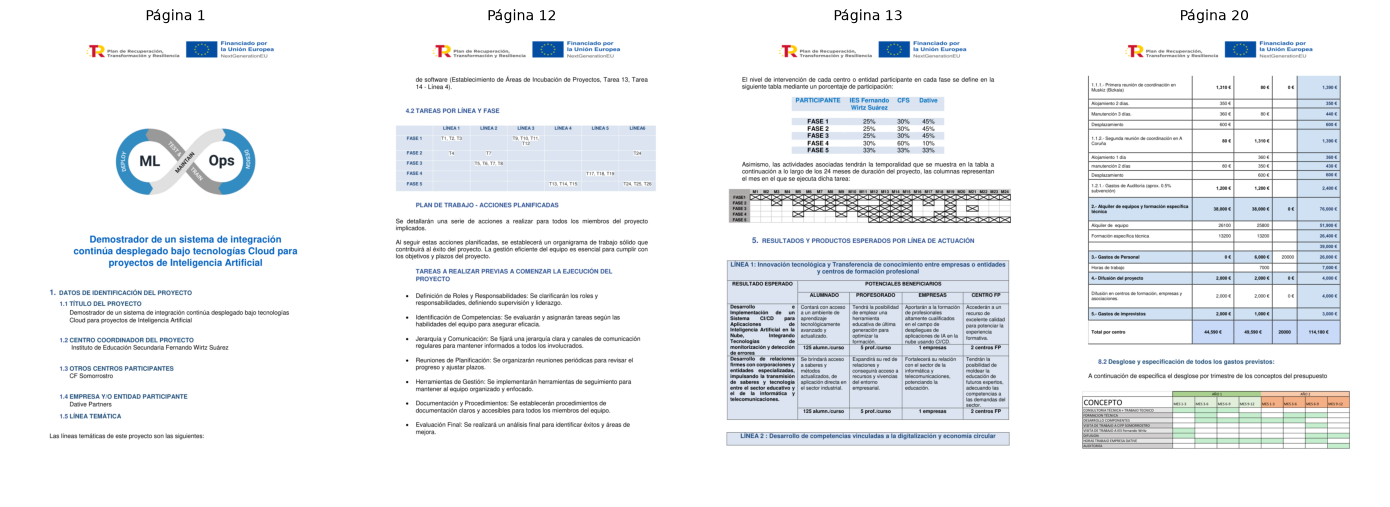

Páginas: 20


In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from rag_lab import pdf

images = pdf.render_pages()
shown_pages = [1, 12, 13, 20]
fig, panels = plt.subplots(1, len(shown_pages), figsize=(14, 5))
for panel, n in zip(panels, shown_pages):
    panel.imshow(Image.open(images[n]))
    panel.set_title(f"Página {n}", fontsize=10)
    panel.axis("off")
plt.tight_layout()
plt.show()
print("Páginas:", len(images))

## 2. Texto plano frente a Docling

Extraer el texto plano (PyMuPDF) pierde la estructura: las tablas salen como una lista de celdas.
Docling analiza la maquetación y devuelve Markdown con cabeceras y tablas. La conversión se cachea en disco;
la primera vez tarda uno o dos minutos.

In [3]:
raw_text = pdf.raw_text_by_page()
print(raw_text[13][:900])

 
 
 
El nivel de intervención de cada centro o entidad participante en cada fase se define en la 
siguiente tabla mediante un porcentaje de participación: 
 
PARTICIPANTE 
IES Fernando 
Wirtz Suárez 
CFS 
Dative  
 
FASE 1 
25% 
30% 
45% 
FASE 2 
25% 
30% 
45% 
FASE 3 
25% 
30% 
45% 
FASE 4 
30% 
60% 
10% 
FASE 5 
33% 
33% 
33% 
 
Asimismo, las actividades asociadas tendrán la temporalidad que se muestra en la tabla a 
continuación a lo largo de los 24 meses de duración del proyecto, las columnas representan 
el mes en el que se ejecuta dicha tarea:  
 
 
5. RESULTADOS Y PRODUCTOS ESPERADOS POR LÍNEA DE ACTUACIÓN 
 
LÍNEA 1: Innovación tecnológica y Transferencia de conocimiento entre empresas o entidades 
y centros de formación profesional 
RESULTADO ESPERADO 
POTENCIALES BENEFICIARIOS 
 ALUMNADO 
PROFESORADO 
EMPRESAS 
CENTRO FP 
Desarrollo 
e 
Implementación 
de 
un 
Sistema 
CI/CD 



In [4]:
doc = pdf.parse()
md_pages = pdf.markdown_by_page(doc)
print(md_pages[13])

<!-- image -->

<!-- image -->

El nivel de intervención de cada centro o entidad participante en cada fase se define en la siguiente tabla mediante un porcentaje de participación:

| PARTICIPANTE   | IES Fernando Wirtz Suárez   | CFS   | Dative   |
|----------------|-----------------------------|-------|----------|
| FASE 1         | 25%                         | 30%   | 45%      |
| FASE 2         | 25%                         | 30%   | 45%      |
| FASE 3         | 25%                         | 30%   | 45%      |
| FASE 4         | 30%                         | 60%   | 10%      |
| FASE 5         | 33%                         | 33%   | 33%      |

Asimismo, las actividades asociadas tendrán la temporalidad que se muestra en la tabla a continuación a lo largo de los 24 meses de duración del proyecto, las columnas representan el mes en el que se ejecuta dicha tarea:

<!-- image -->

## 5. RESULTADOS Y PRODUCTOS ESPERADOS POR LÍNEA DE ACTUACIÓN

LÍNEA 2 : Desarrollo de competencias vin

Comprobamos qué conserva Docling en las páginas con elementos visuales: tablas, marcas del cronograma
(las X) y colores del calendario.

In [5]:
import pandas as pd

tables_by_page = pd.Series([t.prov[0].page_no for t in doc.tables]).value_counts().sort_index()
rows = []
for n in [1, 12, 13, 20]:
    rows.append({
        "página": n,
        "tablas detectadas": int(tables_by_page.get(n, 0)),
        "marcadores de imagen": md_pages[n].count("<!-- image -->"),
        "X en el texto plano": raw_text[n].count("X"),
        "X en el Markdown": md_pages[n].count("X"),
    })
pd.DataFrame(rows).set_index("página")

,tablas detectadas,marcadores de imagen,X en el texto plano,X en el Markdown
página,,,,
1,0,2,0,0
12,1,2,0,0
13,2,3,0,0
20,2,2,0,0


In [6]:
# Calendario de colores (página 20): la tabla llega, pero las celdas coloreadas salen vacías
calendar_table = md_pages[20][md_pages[20].find("| CONCEPTO"):]
print(calendar_table[:1500])

| CONCEPTO                               | AÑO 1 - MES 1-3   | AÑO 1 - MES 3-6   | AÑO 1 - MES 6-9   | AÑO 1 - MES 9-12   | AÑO 2 - MES 1-3   | AÑO 2 - MES 3-6   | AÑO 2 - MES 6-9   | AÑO 2 - MES 9-12   |
|----------------------------------------|-------------------|-------------------|-------------------|--------------------|-------------------|-------------------|-------------------|--------------------|
| CONSULTORIA TÉCNICA + TRABAJO TECNICO  |                   |                   |                   |                    |                   |                   |                   |                    |
| FORMACION TÉCNICA                      |                   |                   |                   |                    |                   |                   |                   |                    |
| DESARROLLO COMPONENTES                 |                   |                   |                   |                    |                   |                   |                 

Conclusión de la salida anterior: Docling conserva las tablas de texto y cifras, pero las marcas que son
dibujos (las X del cronograma) y los colores no son texto: el cronograma queda como un marcador de imagen y el
calendario como una tabla vacía. Esa información solo se recupera mirando la imagen (notebook 7).

## 3. Tres estrategias de chunking

- **Tamaño fijo**: ventanas de 800 caracteres con 100 de solape. Simple, pero corta tablas y frases.
- **Recursivo**: corta por el separador más grueso posible (sección, párrafo, línea, frase) hasta 800 caracteres.
- **Por cabeceras**: un fragmento por sección de Markdown; las tablas nunca se parten.

Cada fragmento guarda las páginas de las que sale, aunque cruce un salto de página.

Antes de trocear, `pdf.clean_pages()` limpia el Markdown de cada página. Entre otras cosas, quita el logo de la
cabecera: Docling a veces lo trocea en varias imágenes dentro del contenido y cada una deja un `<!-- image -->`
que ensucia los fragmentos. Cómo se detecta y se quita está en `anexos/A1_logo_repetido.ipynb`.

In [7]:
from rag_lab import chunking

pages = pdf.clean_pages()
fragments = {name: fn(pages) for name, fn in chunking.STRATEGIES.items()}
pd.DataFrame({name: chunking.summary(fr) for name, fr in fragments.items()}).T

,fragmentos,media_chars,min_chars,max_chars,multipagina
fijo,113,764,143,800,20
recursivo,144,539,80,988,14
cabeceras,63,1256,95,5426,27


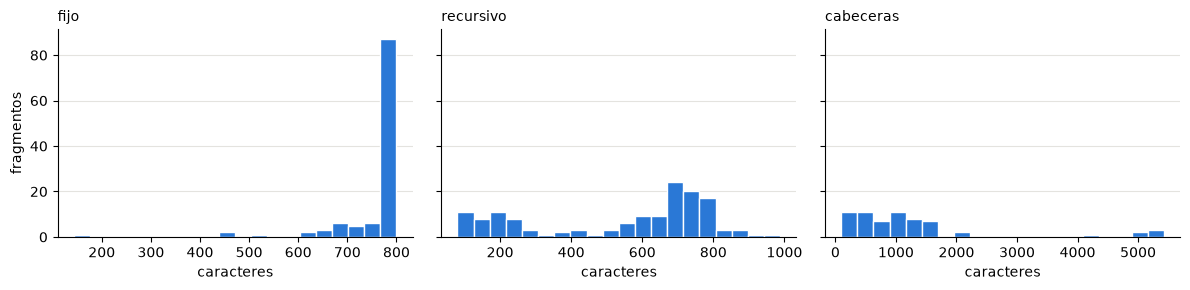

In [8]:
fig, panels = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for panel, (name, fr) in zip(panels, fragments.items()):
    panel.hist([len(f["texto"]) for f in fr], bins=20, color="#2a78d6", edgecolor="white")
    panel.set_title(name, loc="left", fontsize=10)
    panel.set_xlabel("caracteres")
    panel.grid(axis="y", color="#e4e3df")
    panel.set_axisbelow(True)
    for side in ("top", "right"):
        panel.spines[side].set_visible(False)
panels[0].set_ylabel("fragmentos")
plt.tight_layout()
plt.show()

Veamos qué le pasa a la tabla de participación por fase (página 13) en cada estrategia.

In [9]:
for name, fr in fragments.items():
    with_table = [f for f in fr if "FASE 4" in f["texto"] and "%" in f["texto"]]
    print(f"=== {name}: {len(with_table)} fragmento(s) con la fila FASE 4")
    text = with_table[0]["texto"]
    start_pos = max(0, text.find("| PARTICIPANTE") - 150)
    print(text[start_pos:start_pos + 700], "\n")

=== fijo: 1 fragmento(s) con la fila FASE 4
5%                         | 30%   | 45%      |
| FASE 2         | 25%                         | 30%   | 45%      |
| FASE 3         | 25%                         | 30%   | 45%      |
| FASE 4         | 30%                         | 60%   | 10%      |
| FASE 5         | 33%                         | 33%   | 33%      |

Asimismo, las actividades asociadas tendrán la temporalidad que se muestra en la tabla a continuación a lo largo de los 24 meses de duración del proyecto, las columnas representan el mes en el que se ejecuta dicha tarea:

<!-- image -->

## 5. RESULTADOS Y PRODUCTOS ESPERADOS POR LÍNEA DE ACTUACIÓN

LÍNEA 2 : Desarrollo de competencias vinculadas a la digitalización y economía 

=== recursivo: 1 fragmento(s) con la fila FASE 4
El nivel de intervención de cada centro o entidad participante en cada fase se define en la siguiente tabla mediante un porcentaje de participación:

| PARTICIPANTE   | IES Fernando Wirtz Suárez   | CFS  

In [10]:
def split_tables(fragments):
    cuts = 0
    for f in fragments:
        lines = [l for l in f["texto"].splitlines() if l.strip()]
        if lines and (lines[0].lstrip().startswith("|") or lines[-1].lstrip().startswith("|")):
            cuts += 1
    return cuts

for size in [400, 800, 1600]:
    fr = chunking.fixed_size(pages, size=size, overlap=size // 8)
    print(size, len(fr), split_tables(fr))

400 225 100
800 113 63
1600 57 34


## 4. Índice en Chroma persistente: V0 y V1

Cada versión es una clase con la misma interfaz: `answer(question) -> {respuesta, contexto, paginas_recuperadas}`.
Los embeddings (BGE-M3) se calculan una vez y se guardan en una colección de Chroma en `cache/`;
si los fragmentos no cambian, la colección se reutiliza.

In [11]:
from rag_lab import versions

v0 = versions.build("V0")
v1 = versions.build("V1")
print("V0:", v0.search_index.col.name, v0.search_index.col.count(), "fragmentos")
print("V1:", v1.search_index.col.name, v1.search_index.col.count(), "fragmentos")
print("Carpeta del índice:", CFG.DOC_CACHE / "chroma")

V0: fijo--baai-bge-m3 113 fragmentos
V1: cabeceras--baai-bge-m3 63 fragmentos
Carpeta del índice: /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/cache/documento_4cad6871/chroma


In [12]:
question = "¿Qué porcentaje de participación tiene Dative en la fase 4?"
for rag in (v0, v1):
    print(rag.version, "páginas de los 5 primeros fragmentos:", [u["paginas"] for u in rag.retrieve(question)[:5]])

V0 páginas de los 5 primeros fragmentos: [[12, 13], [6, 7], [1, 2], [13], [18, 19]]
V1 páginas de los 5 primeros fragmentos: [[12, 13], [6, 7], [1], [13, 14], [14, 15]]


Y la respuesta de V1. Todas las versiones tienen la misma interfaz: `answer(pregunta)` recupera los fragmentos,
monta el contexto con los 5 primeros y llama al LLM (`GEN_MODEL`).

In [13]:
output = v1.answer(question)
print(output["respuesta"])
print("Páginas de los fragmentos del contexto:", output["paginas_recuperadas"][:5])

Dative tiene un 10% de participación en la fase 4 [p. 12, 13].
Páginas de los fragmentos del contexto: [[12, 13], [6, 7], [1], [13, 14], [14, 15]]


Con una sola pregunta no sabemos si V1 es mejor que V0 en general. En el notebook 3 las evaluamos con
20 preguntas y empezamos la tabla de resultados que irán llenando los demás notebooks.

In [14]:
from rag_lab import models

models.release()

## Qué hemos visto

- Docling conserva cabeceras y tablas, pero pierde lo que es dibujo o color (las X del cronograma, el calendario).
- El chunking por estructura mantiene las tablas enteras y cada fragmento sabe de qué páginas sale.
- Cada versión del RAG tiene la misma interfaz, `answer(pregunta)`, y su índice queda guardado en disco.

## Ejercicio propuesto

Haz tres preguntas tuyas sobre el documento (una de texto, una de tabla y una sobre el cronograma) a V0 y a V1.
Anota qué páginas recupera cada versión y si la respuesta es correcta. En el notebook 3 veremos cómo medir esto
con muchas preguntas a la vez.